In [ ]:
!pip install keras

# 1.Import Libraries

In [ ]:
import keras
import warnings
warnings.filterwarnings('ignore')
from matplotlib import pyplot as plt
import numpy as np
from keras.layers import Conv2D,MaxPool2D,UpSampling2D
from keras.models import Sequential

# 2. Data Collection

In [ ]:
(X_train,_),(X_test,_)=keras.datasets.cifar10.load_data()


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1364s 8us/step


In [ ]:
X_train.shape,X_test.shape

((50000, 32, 32, 3), (10000, 32, 32, 3))

# 3. Data Preparation

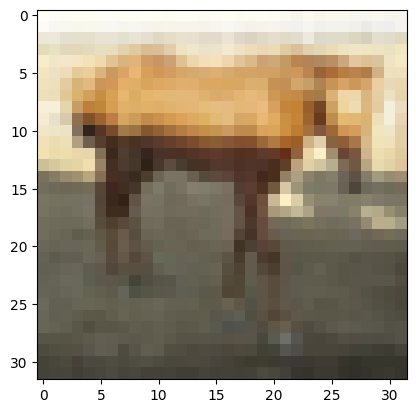

In [ ]:
plt.imshow(X_train[2000])

## 3.1 Normalize the pixel values

In [ ]:
X_train.max(),X_train.min()

(np.uint8(255), np.uint8(0))

In [ ]:
X_test.max(),X_test.min()

(np.uint8(255), np.uint8(0))

In [ ]:
X_train = X_train/255.0
X_test = X_test/255.0

In [ ]:
X_test.max(),X_test.min()

(np.float64(1.0), np.float64(0.0))

In [ ]:
X_train.max(),X_train.min()

(np.float64(1.0), np.float64(0.0))

## 3.2 Add noise to data

In [ ]:
X_train_noise = X_train + 0.2 * np.random.normal(loc=0.0, scale=1.0, size=X_train.shape)
X_test_noise = X_test + 0.2 * np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)

In [ ]:
X_test_noise.max(),X_test_noise.min()

(np.float64(1.9388753901477376), np.float64(-1.0034844038953705))

In [ ]:
X_train_noise.max(),X_train_noise.min()

(np.float64(1.9792522279563314), np.float64(-1.0110842625682213))

## 3.3 Add clip to noise data

In [ ]:
X_train_clipped=np.clip( X_train_noise,a_min=0.,a_max=1.)
X_test_clipped=np.clip( X_test_noise,a_min=0.,a_max=1.)

In [ ]:
X_train_clipped.max(),X_train_clipped.min()

(np.float64(1.0), np.float64(0.0))

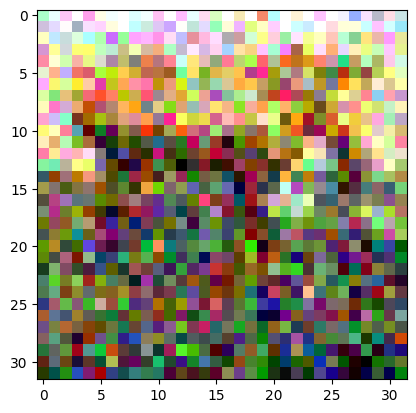

In [ ]:
plt.imshow(X_train_clipped[2000])

# 4. Model Building

In [ ]:
model = Sequential()
#Encoder
model.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',input_shape = (32, 32, 3)))
model.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Conv2D(filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',))
model.add(Conv2D(filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))

#Decoder
model.add(Conv2D(filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(Conv2D(filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(UpSampling2D(size=(2, 2)))
model.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',))
model.add(Conv2D(filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(UpSampling2D(size=(2, 2)))
model.add(Conv2D(filters=3,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 8)      │         2,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 32)     │         2,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,659 (104.14 KB)

 Trainable params: 26,659 (104.14 KB)

 Non-trainable params: 0 (0.00 B)

# 5. Model Compile

In [ ]:
model.compile( optimizer='adam',loss='mean_squared_error',metrics=['accuracy'])

# 6. Model Training

In [ ]:
model.fit(x=X_train_clipped,y=X_train,batch_size=32,epochs=5,validation_data=(X_test_clipped,X_test))

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.5385 - loss: 0.0144 - val_accuracy: 0.6445 - val_loss: 0.0087
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6414 - loss: 0.0082 - val_accuracy: 0.6785 - val_loss: 0.0075
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6965 - loss: 0.0073 - val_accuracy: 0.6561 - val_loss: 0.0071
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7079 - loss: 0.0069 - val_accuracy: 0.7233 - val_loss: 0.0066
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7137 - loss: 0.0065 - val_accuracy: 0.7276 - val_loss: 0.0063


# 7. Model Evaluation

In [ ]:
model.evaluate(X_test_clipped,X_test)

ValueError: None values not supported.

# 8. Model Prediction

In [ ]:
y_pred=model.predict(X_test_clipped)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


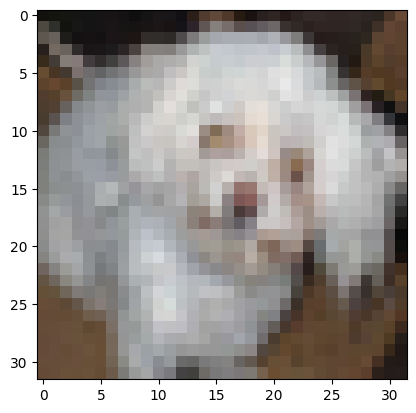

In [ ]:
plt.imshow(X_test[1000])

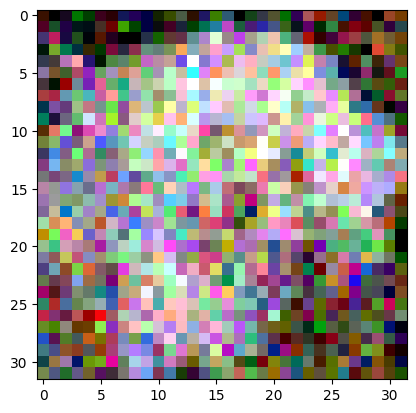

In [ ]:
plt.imshow(X_test_clipped[1000])

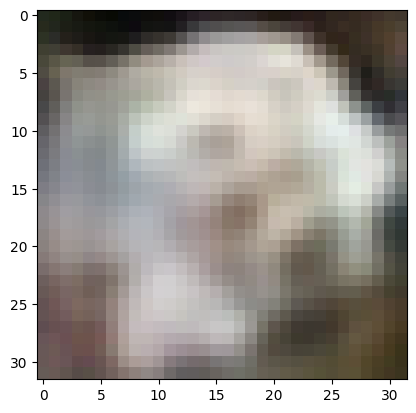

In [ ]:
plt.imshow(y_pred[1000],cmap = 'grey')

# 9. Save Model

In [ ]:
model.save('denoise_color.h5')